# Curvas de Transferencia — EGOFET

Análisis de curvas $I_{DS}$ vs $V_{GS}$ a $V_{DS}$ constante.
De aquí extraemos: $V_{th}$, movilidad, $SS$, relación $I_{on}/I_{off}$.

In [1]:
# === Paso 1: Setup: imports, rutas, listar archivos ===
import os
import sys
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Para hacer 'from src import ...', Python necesita que el project root
# este en sys.path. Jupyter no lo agrega solo, asi que lo añadimos a mano.
# Truco: subimos desde CWD hasta encontrar un directorio que contenga 'src'.
# Asi funciona sin importar desde donde se haya lanzado el kernel.

def find_project_root(marker='src'):
    cwd = Path(os.getcwd()).resolve()
    for parent in [cwd, *cwd.parents]: # Va hacia atras hasta encontrar el root donde se encuentra el marker
        if (parent / marker).is_dir():
            return parent
    raise FileNotFoundError(
        f"No se encontro el project root con marcador '{marker}'. "
        f"Partiendo de: {cwd}"
    )

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

# importamos librerias locales de src
from src.readers.keithley_dean import list_measurements, read_curve, read_all_curves, view_measurements
from src.readers import print_structure
from src.plotting import plot_transfer, plot_grid

data_folder = PROJECT_ROOT / 'data' / 'raw'

print(f"Project root: {PROJECT_ROOT}")
print(f"Data folder:   {data_folder}")
print("Archivos disponibles:")
for f in sorted(os.listdir(data_folder)):
    print(f"  {f}")

Project root: /home/dibarra/Documents/egofets-project
Data folder:   /home/dibarra/Documents/egofets-project/data/raw
Archivos disponibles:
  2026-06-26_test1.hdf5
  2026-06-29_test2.1.hdf5
  2026-06-29_test2.hdf5
  2026-06-30_test3.hdf5
  2026-07-01_test3.hdf5
  2026-07-08_biosensing_10_-6.hdf5
  2026-07-08_biosensing_10_-6_v2.hdf5
  2026-07-08_test.hdf5
  2026-07-16_testkapton.hdf5
  2026-07-22_kapton_and_old.hdf5
  2026-07-22_kapton_v2.hdf5
  2026-07-22_kapton_v3.hdf5
  2026-07-23 TMTES PS Phototransistor v3.hdf5
  2026-08-13_test2_kapton_v3.hdf5
  2026-09-04_kapton_test_out.hdf5
  2026-10-02_test.hdf5
  2026-10-21_SensingB2-edit.hdf5
  2026-10-21_SensingB2.hdf5
  2026-10-21_sensing-edit.hdf5
  2026-10-21_sensing.hdf5
  2026-10-22_sensingB3-edit.hdf5
  2026-10-22_sensingB3.hdf5
  2026-10-23_sensingB4_v2.hdf5
  notas.txt


In [2]:
# === Paso 2: Abrir HDF5 y listar SOLO los grupos top-level (mediciones) ===
# Cada grupo top-level es una medicion distinta (transfer, output, o stability)

hdf5_name = "2026-06-30_test3.hdf5"
hdf5_path = os.path.join(data_folder, hdf5_name)

view_measurements(hdf5_path)

Archivo: 2026-06-30_test3.hdf5
Mediciones encontradas (21):

  010626_batch1_mta1_00                               mode=transfer    curves=2
  010626_batch1_mta1_01                               mode=output      curves=7
  010626_batch1_mta1_02                               mode=desconocido  curves=0
  010626_batch1_mta1_03                               mode=transfer    curves=2
  010626_batch1_mta1_04                               mode=output      curves=7
  010626_batch1_mta1_05                               mode=desconocido  curves=0
  010626_batch2_mta1_00                               mode=transfer    curves=2
  010626_batch2_mta1_01                               mode=output      curves=7
  010626_batch2_mta1_02                               mode=transfer    curves=2
  010626_batch2_mta1_03                               mode=output      curves=7
  010626_batch3_mta1_00                               mode=transfer    curves=2
  010626_batch3_mta1_01                               mod

'  010626_batch1_mta1_00                               mode=transfer    curves=2\n  010626_batch1_mta1_01                               mode=output      curves=7\n  010626_batch1_mta1_02                               mode=desconocido  curves=0\n  010626_batch1_mta1_03                               mode=transfer    curves=2\n  010626_batch1_mta1_04                               mode=output      curves=7\n  010626_batch1_mta1_05                               mode=desconocido  curves=0\n  010626_batch2_mta1_00                               mode=transfer    curves=2\n  010626_batch2_mta1_01                               mode=output      curves=7\n  010626_batch2_mta1_02                               mode=transfer    curves=2\n  010626_batch2_mta1_03                               mode=output      curves=7\n  010626_batch3_mta1_00                               mode=transfer    curves=2\n  010626_batch3_mta1_01                               mode=output      curves=7\n  010626_batch3_mta1_02  

In [3]:
# === Paso 3: Leer una curva transfer ===
# Probamos función para extraer datos de transfer

measurement_name = "010626_batch1_mta1_00"
curve_name = "curve_000"

v_gs, i_ds = read_curve(hdf5_path, measurement_name, curve_name,
                        curve_type="transfer", direction="both")

dic_data = {
    "gate voltaje": v_gs,
    "current drain": i_ds
            }

df = pd.DataFrame(dic_data)
print(df) # Esto solo como ejemplo de que se pueden obtener estos datos para su graficacion

# fig, ax = plt.subplots()

# ax.plot(df["gate voltaje"], df["current drain"], label="curve 000")
# ax.set_title("Transfer curve - " + measurement_name)

#plt.show()

     gate voltaje  current drain
0        0.400188  -1.295800e-09
1        0.390027  -4.982950e-10
2        0.380208   6.556510e-11
3        0.370028  -6.914140e-11
4        0.360167   2.741810e-11
..            ...            ...
157      0.360188  -1.870390e-09
158      0.370069  -1.797680e-09
159      0.380220  -1.785760e-09
160      0.390036  -1.835820e-09
161      0.400193  -2.069470e-09

[162 rows x 2 columns]


In [4]:
# === Paso 3.1: Obtener un punto de una curva transfer ===

V_READ = -0.3  # V_GS de lectura (V), preferiblemente dentro de la zona encendida

v_gs, i_ds = read_curve(hdf5_path, measurement_name, curve_name,
                        curve_type="transfer", direction="fwd")

pt = np.interp(V_READ, v_gs, i_ds)  # Interpolación lineal para obtener I_DS en V_READ
print(f"En V_GS = {V_READ:.2f} V, I_DS = {pt:.2e} A")

En V_GS = -0.30 V, I_DS = -1.77e-06 A


(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Transfer — 010626_batch1_mta1_00'}, xlabel='$V_{GS}$ (V)', ylabel='$I_{DS}$ (A)'>)

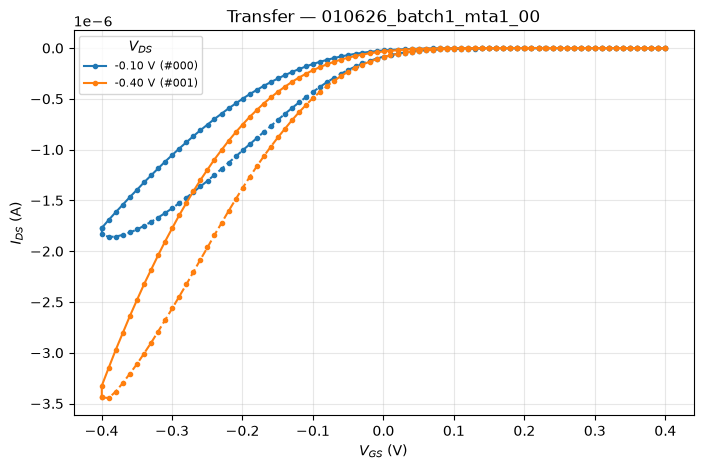

In [5]:
# === Paso 4: graficar datos con funciones de src ===
measurement_name = "010626_batch1_mta1_00"

plot_transfer(hdf5_path, measurement_name)


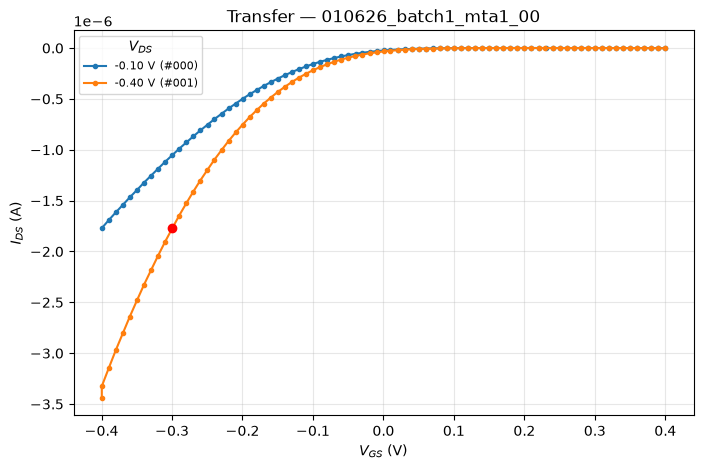

In [6]:
# Graficar la curva transfer en un sentido. Con un punto de la gráfica.
fig, ax = plot_transfer(hdf5_path, measurement_name, direction="fwd")

ax.plot(V_READ, pt, 'ro', label=f"V_GS={V_READ:.2f} V, I_DS={pt:.2e} A")

['010626_batch1_mta1_00', '010626_batch1_mta1_03', '010626_batch2_mta1_00', '010626_batch2_mta1_02', '010626_batch3_mta1_00', '010626_batch3_mta1_03', '010626_batch4_mta1_00', '010626_batch4_mta1_02', '010626_batch4_mta1_03']


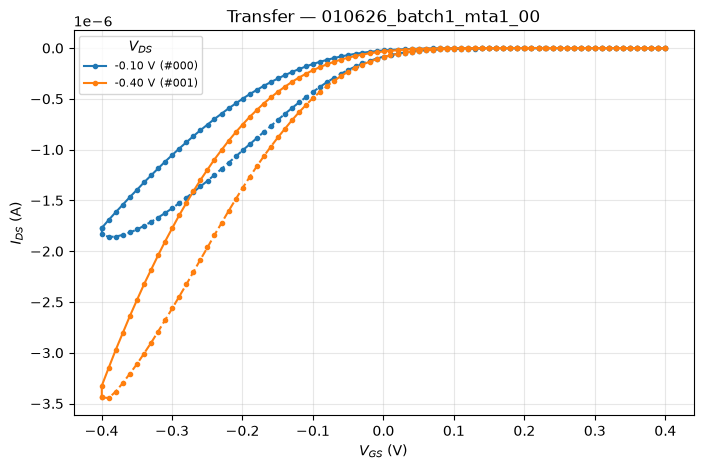

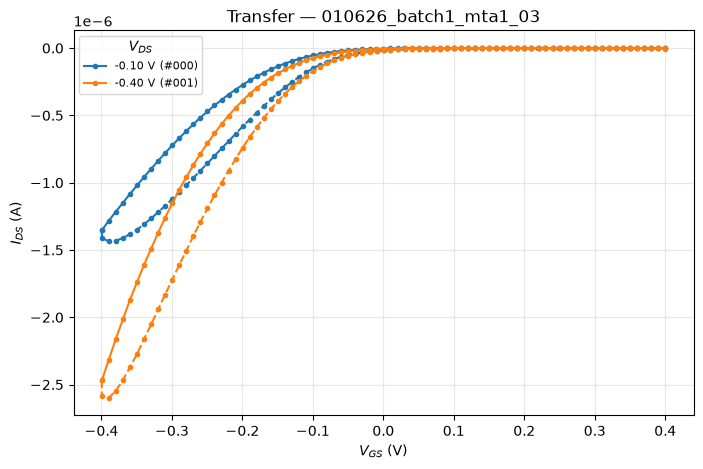

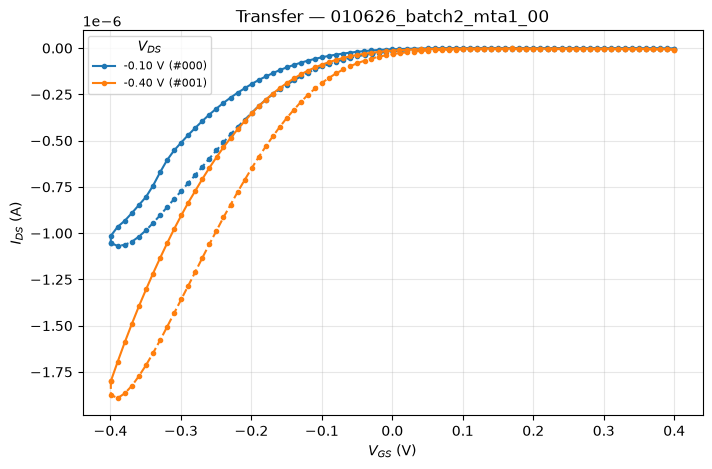

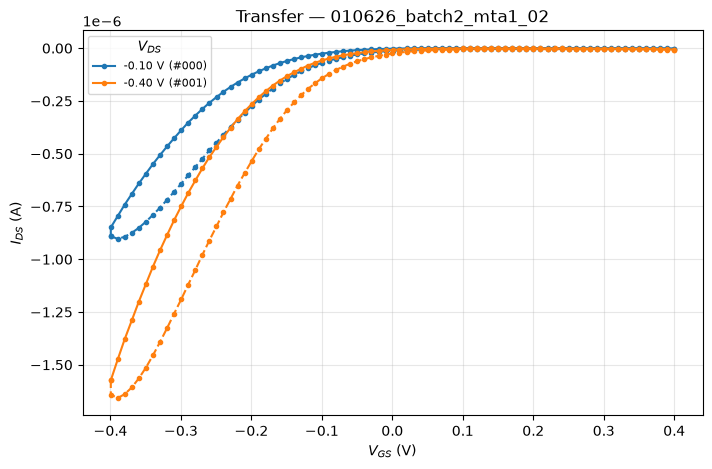

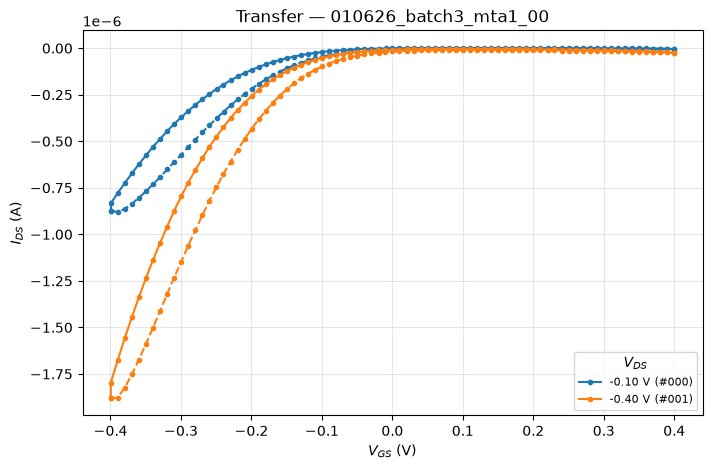

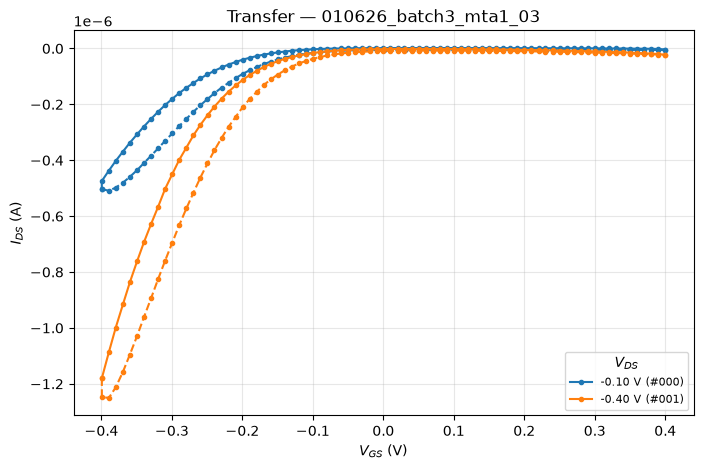

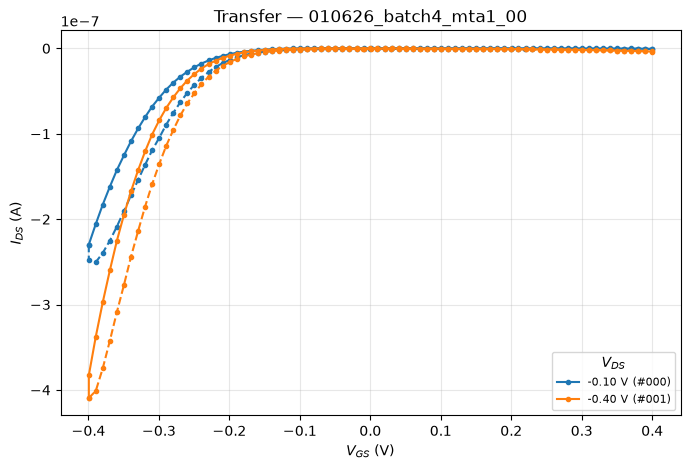

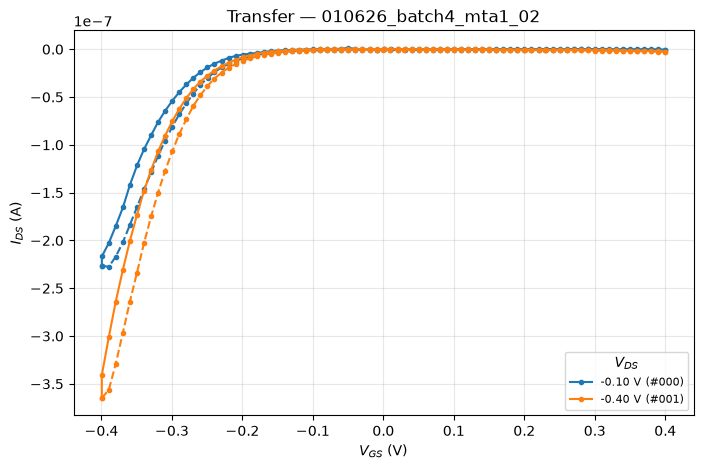

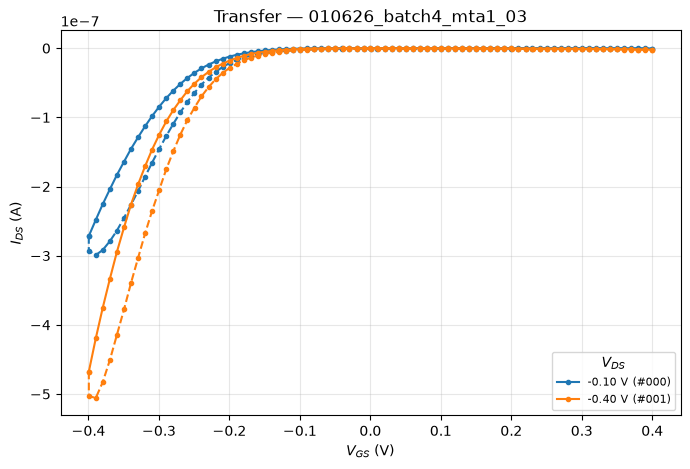

In [7]:
# === Paso 5: graficar una lista con los batch a observar ===
measurement_list_dic = list_measurements(hdf5_path)

measurement_list_names = [measurement["name"] for measurement in measurement_list_dic if measurement["mode"] == "transfer"]
print(measurement_list_names)

measurements_name_issue = []

for measurement_name in measurement_list_names:
    try:
        plot_transfer(hdf5_path, measurement_name)
    except TypeError:
        print(f"Couldn't plot {measurement_name} due to a TypeError")
        measurements_name_issue.append(measurement_name)
        continue

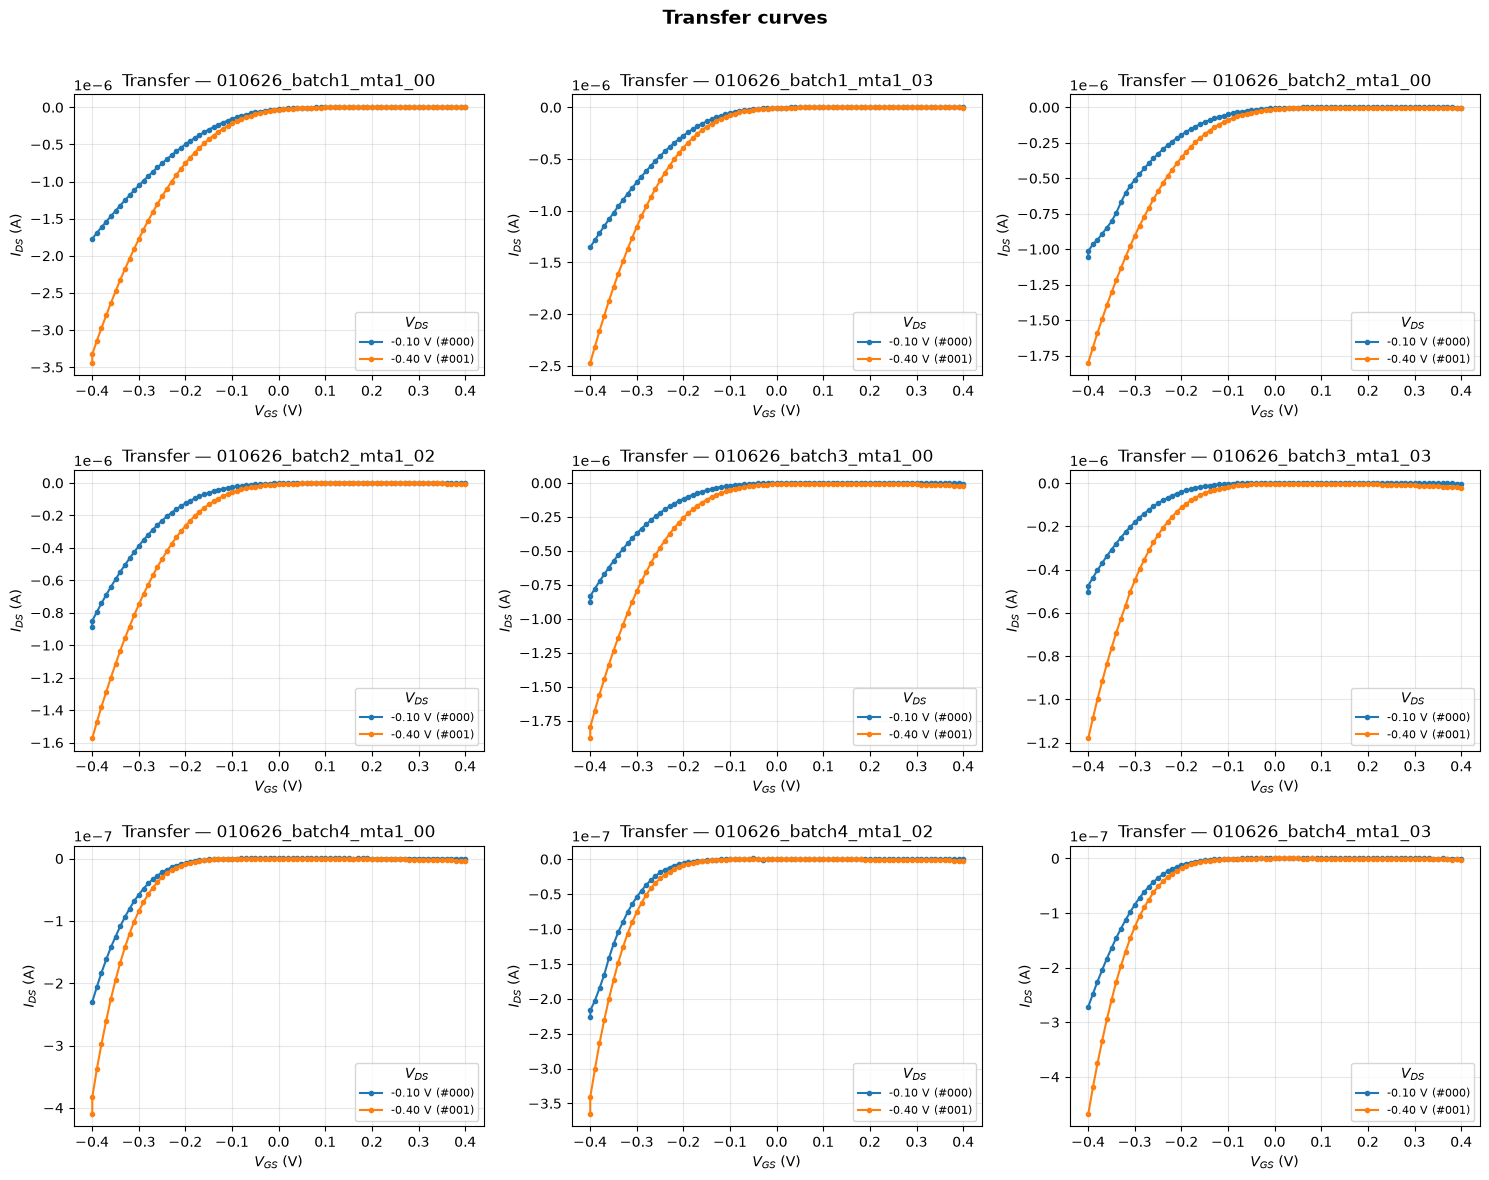

In [8]:
# Acomodamos en una grilla de subplots, para ver varias curvas transfer en la misma figura.
measurement_list_dic = list_measurements(hdf5_path)
transfer_measurements = [m["name"] for m in measurement_list_dic if m["mode"] == "transfer"]

fig = plot_grid(hdf5_path, transfer_measurements, plot_transfer, ncols=3, title_suffix="Transfer curves")
plt.show()

## Extracción de parámetros

### $V_{th}$ — $\sqrt{I_{DS}}$ (saturación)

### Marco teórico: Regímenes de operación del FET

En un transistor de efecto de campo, la operación se divide en dos regímenes según la condición:

$$|V_{DS}| \geq |V_{GS} - V_{th}| \quad \text{(saturación)}$$

En **saturación**, y suponiendo movilidad constante, la corriente drenaje-fuente sigue la **ley cuadrática**:

$$|I_{DS}^{sat}| = \frac{1}{2}\,\mu_{sat}\,C\,\frac{W}{L}\,(V_{GS} - V_{th})^2$$

Donde:
- $\mu_{sat}$: movilidad de los portadores en saturación (cm²/V·s)
- $C$: capacitancia por unidad de área de la doble capa eléctrica (F/cm²). En un EGOFET es mucho mayor que en un MOSFET porque la EDL es del orden de nanómetros. El medio acuoso es el capacitor.
- $W$, $L$: ancho y largo del canal (cm)
- $V_{th}$: threshold voltage. En tu dispositivo tipo p es **negativo**


In [9]:
# Realizar extracción de saturación para una sola muestra
print("Analizando muestra: " + measurement_name)

curves = read_all_curves(hdf5_path, measurement_name)

i_max = max(range(len(curves)), key=lambda i: abs(curves[i]['v_ds'][0])) # Es el primer valor porque se repite para todas las mediciones.
curve = curves[i_max]
v_gs, i_ds, v_ds = curve['v_gs'], curve['i_ds'], curve['v_ds']
print(f"Usando V_DS = {v_ds[0]} V\ncurve={curve.keys()}") # Es el transfer más alto que asegura el régimen saturado para obtener el V_th


Analizando muestra: 010626_batch4_mta1_03
Usando V_DS = -0.400181 V
curve=dict_keys(['v_gs', 'i_ds', 'v_ds', 'curve_name'])


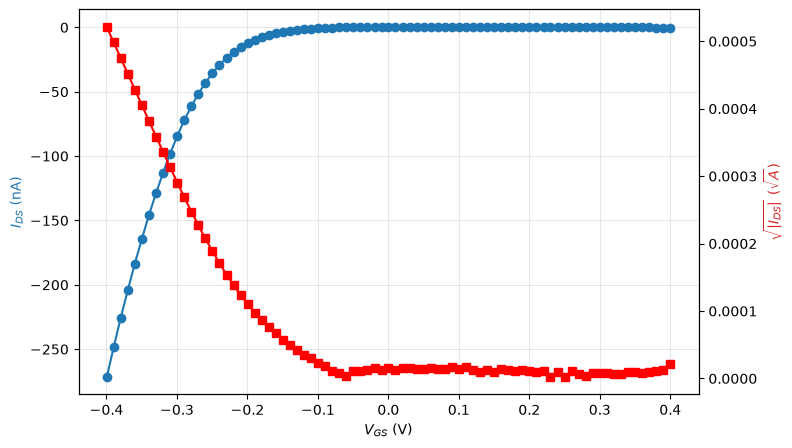

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
v_gs_fwd, i_ds_fwd = read_curve(hdf5_path, measurement_name, direction='fwd')
# plot 1: I_DS vs V_GS (la transfer normal)
ax.plot(v_gs_fwd, i_ds_fwd * 1e9, 'o-', label=r'$I_{DS}$')
# plot 2: sqrt(|I_DS|) vs V_GS, mismo eje x
ax2 = ax.twinx()
sqrt_ids = np.sqrt(np.abs(i_ds_fwd))
ax2.plot(v_gs_fwd, sqrt_ids, 'rs-', label=r'$\sqrt{|I_{DS}|}$')
ax.set_xlabel(r'$V_{GS}$ (V)')
ax.set_ylabel(r'$I_{DS}$ (nA)', color='C0')
ax2.set_ylabel(r'$\sqrt{|I_{DS}|}$ ($\sqrt{A}$)', color='C3')
ax.grid(True, alpha=0.3)


### Linealización: el método $\sqrt{|I_{DS}|}$

Tomando raíz cuadrada de la ley cuadrática, se obtiene una relación **lineal** en $V_{GS}$:

$$\sqrt{|I_{DS}|} = \underbrace{\sqrt{\tfrac{1}{2}\mu_{sat}\,C\,\tfrac{W}{L}}}_{\text{pendiente } m} \cdot (V_{GS} - V_{th})$$

En la región de encendido ($V_{GS} > V_{th}$ para tipo p, donde $V_{th} < 0$), esta expresión es una **recta** con:
- **pendiente** $m$ (relacionada con la movilidad)
- **intercepto en el eje $V_{GS}$** en $V_{GS} = V_{th}$ (donde $\sqrt{|I_{DS}|} = 0$)

Por eso graficamos $\sqrt{|I_{DS}|}$ vs $V_{GS}$: para **linealizar la parábola** y extraer $V_{th}$ con una regresión lineal.


### $V_{th}$ — Método lineal

De forma "automática" vamos a replicar encontrar la regresión lineal con mejor ajuste con la segunda derivada de la función original.

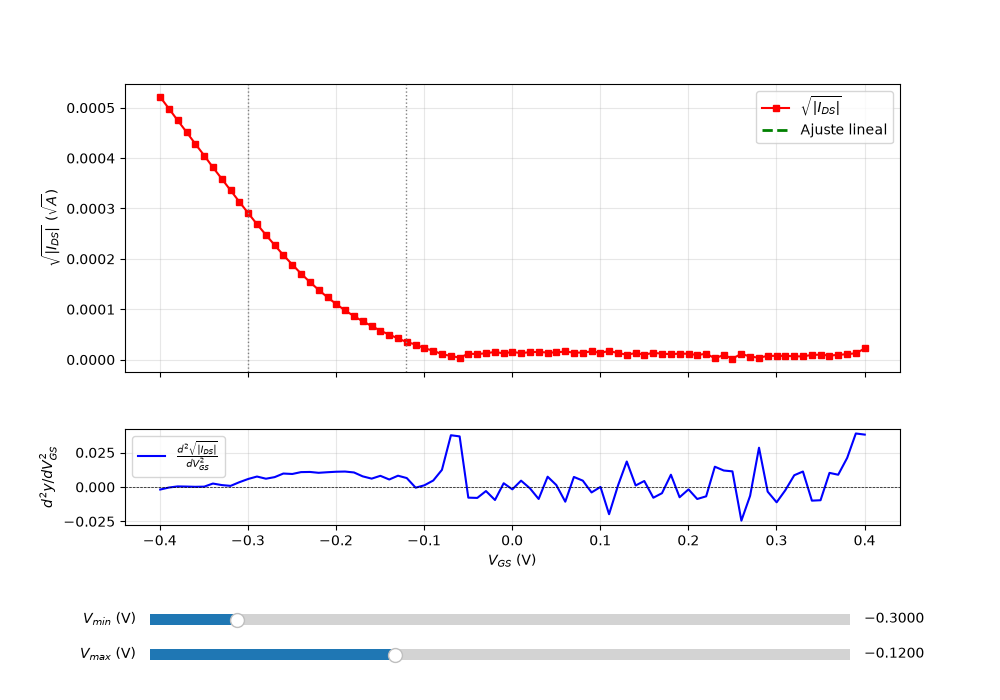

In [11]:
# Activa el backend interactivo de matplotlib para que los sliders funcionen
# (necesita tener instalado ipympl: pip install ipympl)
%matplotlib widget

from matplotlib.widgets import Slider
from scipy.stats import linregress

# ====================================================================
# DATOS: usamos los que ya cargamos en la celda 7
#   x = V_GS del forward sweep
#   y = sqrt(|I_DS|), que es lo que se lineariza en saturacion
# ====================================================================
x = v_gs_fwd
y = sqrt_ids

# ====================================================================
# VENTANA INICIAL: estos valores los elegiste a ojo en la celda 8.
# Son el punto de partida del slider; los moveras interactivamente.
# ====================================================================
v_min_init = -0.30
v_max_init = -0.12

# ====================================================================
# FIGURA: dos subplots apilados
#   - Arriba: datos + ajuste lineal dentro de la ventana
#   - Abajo:  segunda derivada numerica (referencia visual)
# ====================================================================
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}  # el de arriba 3x mas alto
)
plt.subplots_adjust(bottom=0.25, hspace=0.3)  # espacio para los sliders

# ----- Subplot superior: datos y ajuste -----
line_data, = ax1.plot(x, y, 'rs-', ms=4, label=r'$\sqrt{|I_{DS}|}$')
line_fit,  = ax1.plot([], [], 'g--', lw=2, label='Ajuste lineal')
# Lineas verticales que muestran los extremos de la ventana (se actualizan con el slider)
line_vmin = ax1.axvline(v_min_init, color='gray', ls=':', lw=1)
line_vmax = ax1.axvline(v_max_init, color='gray', ls=':', lw=1)
ax1.set_ylabel(r'$\sqrt{|I_{DS}|}$ ($\sqrt{A}$)')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Cuadro de texto con V_th y R^2 (se actualiza dentro de update)
text_results = ax1.text(
    0.02, 0.95, '', transform=ax1.transAxes,
    fontsize=10, verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.7)
)

# ----- Subplot inferior: segunda derivada numerica -----
# np.gradient calcula d(y)/d(x) numericamente.
# Lo aplicamos dos veces para obtener la segunda derivada.
# Donde d^2 ~= 0, la curva es mas lineal (esa es la region que queremos ajustar).
d2 = np.gradient(np.gradient(y, x), x)
ax2.plot(x, d2, 'b-', lw=1.5, label=r"$\frac{d^2\sqrt{|I_{DS}|}}{dV_{GS}^2}$")
ax2.axhline(0, color='k', lw=0.5, ls='--')
ax2.set_xlabel(r'$V_{GS}$ (V)')
ax2.set_ylabel(r'$d^2 y / dV_{GS}^2$')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

# ====================================================================
# SLIDERS: controlan los extremos de la ventana de ajuste
# ====================================================================
# Posicion [izquierda, abajo, ancho, alto] en coords de la figura (0-1)
ax_vmin = plt.axes([0.15, 0.10, 0.7, 0.03])
ax_vmax = plt.axes([0.15, 0.05, 0.7, 0.03])
slider_vmin = Slider(ax_vmin, r'$V_{min}$ (V)', float(x.min()), float(x.max()),
                     valinit=v_min_init)
slider_vmax = Slider(ax_vmax, r'$V_{max}$ (V)', float(x.min()), float(x.max()),
                     valinit=v_max_init)

# ====================================================================
# UPDATE: se ejecuta cada vez que se mueve un slider
# ====================================================================
def update(val):
    v_min = slider_vmin.val
    v_max = slider_vmax.val

    # Validaciones: ventana invalida (vacia o invertida)
    if v_min >= v_max:
        return
    mask = (x >= v_min) & (x <= v_max)
    if mask.sum() < 3:  # muy pocos puntos para ajustar
        return

    # Ajuste lineal (minimos cuadrados) en la ventana seleccionada
    x_win, y_win = x[mask], y[mask]
    slope, intercept, r_value, _, _ = linregress(x_win, y_win)

    # V_th: x-intercepto de la recta ajustada (donde y = 0)
    v_th = -intercept / slope

    # Actualizar las lineas del plot con el nuevo ajuste
    line_fit.set_data(x_win, slope * x_win + intercept)
    line_vmin.set_xdata([v_min])
    line_vmax.set_xdata([v_max])

    # Actualizar el cuadro de texto con los resultados
    text_results.set_text(
        f'$V_{{th}}$ = {v_th:.3f} V\n'
        f'$R^2$ = {r_value**2:.4f}\n'
        f'Puntos en ventana: {mask.sum()}'
    )

    # Redibujar la figura (draw_idle es mas eficiente que draw_reload)
    fig.canvas.draw_idle()

# Conectar los sliders a la funcion update
slider_vmin.on_changed(update)
slider_vmax.on_changed(update)

plt.show()


De forma manual, elegiremos la ventana de regresión según veamos el gráfico de transfer y $\sqrt{I_{DS}}$ cómo cambia de la sección plana a lineal.

/tmp/ipykernel_121874/2401905359.py:14: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  ax.plot(v_gs_fwd[mask], intercept + slope * v_gs_fwd[mask], "r--", color="green", label="linear fit")


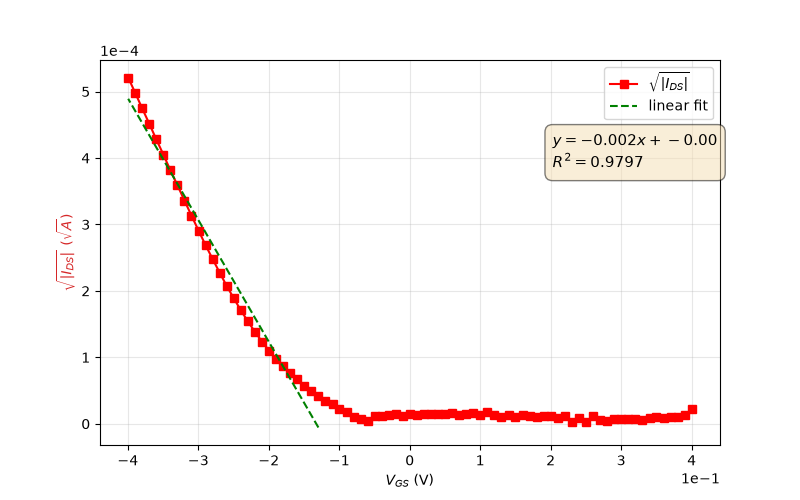

In [12]:
# Elegimos una ventana de ajsute
mask = (v_gs_fwd > -0.4) & (v_gs_fwd < -0.12)

# Aplicamos regresión lineal y extraemos valores
slope, intercept, r_value, _, _ = linregress(v_gs_fwd[mask], sqrt_ids[mask])

txt_fit_data = (f'$y = {slope:.3f}x + {intercept:.2f}$\n'
               f'$R^2 = {r_value**2:.4f}$')

# Ploteamos en el gráfico existente
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(v_gs_fwd, sqrt_ids, 'rs-', label=r'$\sqrt{|I_{DS}|}$')

ax.plot(v_gs_fwd[mask], intercept + slope * v_gs_fwd[mask], "r--", color="green", label="linear fit")

ax.text(0.73, 0.72, s=txt_fit_data, transform=ax.transAxes, fontsize=11, bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))

ax.set_ylabel(r'$\sqrt{|I_{DS}|}$ ($\sqrt{A}$)', color='C3')
ax.set_xlabel(r'$V_{GS}$ (V)')
ax.axes.ticklabel_format(style="sci", scilimits=(-3,-4))
ax.legend()
ax.grid(True, alpha=0.3)

### De la pendiente a $V_{th}$ y a la movilidad

Del ajuste lineal $y = mx + b$ sobre $\sqrt{|I_{DS}|}$ vs $V_{GS}$:

$$V_{th} = -\frac{b}{m}$$

**Movilidad en saturación**:

$$\mu_{sat}C = \frac{2L}{W} \cdot m^2$$

> **Unidades**: si $W$, $L$ están en m y $C$ en F/m², $\mu_{sat}$ sale en m²/V·s. Para reportar en cm²/V·s, multiplicar por $10^4$.


In [13]:
# Si el V_th es cuando y=0=mx+b entonces
v_th = - intercept / slope
print(f"V_th = {v_th:.3f} V")

# como el dieléctrico es el medio acuoso, C forma parte del resultado de la movilidad 
# (usar unidades consistentes: W, L en m; C en F/m²)
#mu_sat_m2 = (2 * L * m**2) / (C * W)   #C * m²/V·s
#mu_sat_cm2 = mu_sat_m2 * 1e4           # cm²/V·s
#print(f"mu_sat = {mu_sat_cm2:.3e} cm²/V·s")

V_th = -0.133 V


### Subthreshold Swing

El **subthreshold swing** ($SS$) cuantifica qué tan rápido transiciona el transistor de off a on. Se define como el inverso de la pendiente máxima del $\log_{10}(I_{DS})$ vs $V_{GS}$ en la región subumbral:

$$SS = \left[\frac{d(\log_{10}|I_{DS}|)}{dV_{GS}}\right]^{-1}_{\max} \quad \text{(V/dec)}$$

Cuanto menor es $SS$, mejor el transistor. En EGOFETs típicamente se obtienen valores entre 0.1 y 1 V/dec.


### Relación $I_{on}/I_{off}$

La **relación $I_{on}/I_{off}$** compara la corriente en estado de encendido vs apagado:

$$\frac{I_{on}}{I_{off}} = \frac{|I_{DS}(V_{GS,\max})|}{|I_{DS}(V_{GS,\min})|}$$

Típicamente $I_{on}$ se toma a $V_{GS}$ máximo del barrido e $I_{off}$ a $V_{GS}$ mínimo. Es un indicador de la "calidad" del switch: cuanto mayor, mejor la modulación del transistor.


## Comparativa entre batches

In [14]:
# === Loop de extraccion de V_th con ventana definida por rangos manuales ===
from src.analysis import extract_vth_for_transfers

df_vth = extract_vth_for_transfers(
    hdf5_path, measurement_list_names,
    v_min_range=(-0.40, -0.20),
    v_max_range=(-0.15, -0.05),
)
display(df_vth)

# Guardar a CSV
import os
os.makedirs(PROJECT_ROOT / 'output', exist_ok=True)
csv_path = PROJECT_ROOT / 'output' / 'vth_all_transfers.csv'
df_vth.to_csv(csv_path, index=False)
print(f"\nGuardado en {csv_path}")


,measurement,V_DS (V),V_th (V),v_min (V),v_max (V),R^2,n_points
0,010626_batch1_mta1_00,-0.400143,0.002911,-0.21,-0.15,0.999852,6
1,010626_batch1_mta1_03,-0.400221,-0.041867,-0.21,-0.15,0.999552,6
2,010626_batch2_mta1_00,-0.400207,-0.021794,-0.24,-0.15,0.999689,9
3,010626_batch2_mta1_02,-0.400066,-0.033981,-0.21,-0.15,0.999597,6
4,010626_batch3_mta1_00,-0.400090,-0.042632,-0.21,-0.15,0.998936,6
5,010626_batch3_mta1_03,-0.400136,-0.069148,-0.21,-0.15,0.998559,6
6,010626_batch4_mta1_00,-0.400176,-0.114560,-0.21,-0.15,0.991948,6
7,010626_batch4_mta1_02,-0.400167,-0.110934,-0.21,-0.15,0.994888,6
8,010626_batch4_mta1_03,-0.400181,-0.101619,-0.21,-0.15,0.996425,6



Guardado en /home/dibarra/Documents/egofets-project/output/vth_all_transfers.csv


## Transconductancia en transistores

La transconductancia se define como la relación entre la variación de la corriente en la salida y la variación de la tensión en su entrada. En los FETs, se mide cómo varía la corriente de drenador-fuente ($I_{d}$) frente a un cambio en la tensión puerta-fuente ($V_{gs}$).

$$
g_{m} = \frac{\delta I_{DS}}{\delta V_{GS}}
$$

Para fines de curvas de calibración, esto puede llegar a ser útil para definir el valor con mayor sensibilidad a cambios de corriente.


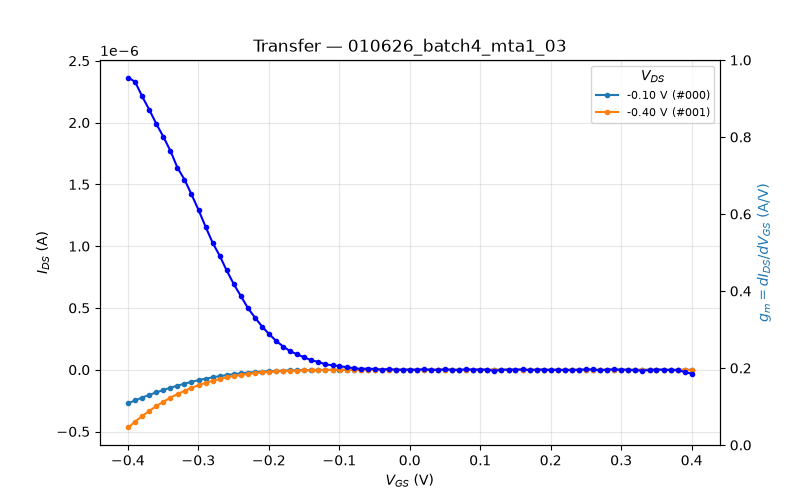

Transconductancia máxima: V_gs = -0.40 V, g_m = 2.36e-06 A/V


In [17]:
fig, ax = plot_transfer(hdf5_path, measurement_name, direction='fwd')
v_gs_fwd, i_ds_fwd = read_curve(hdf5_path, measurement_name, direction='fwd')

# Al tener los datos un espaciado uniforme, podemos usar np.gradient para calcular la derivada numérica
transconductance = np.gradient(i_ds_fwd, v_gs_fwd)  # dI_DS/dV_GS

ax.plot(v_gs_fwd, transconductance, 'o-', ms=3, color='blue', label='Transconductance')
secondary_ax = ax.twinx()
secondary_ax.set_ylabel(r'$g_m = dI_{DS}/dV_{GS}$ (A/V)', color='C0')
ax.grid(True, alpha=0.3)

plt.show()

# Best point to read current.
idx_max = np.argmax(transconductance)
v_gs_max = v_gs_fwd[idx_max]
gm_max = transconductance[idx_max]

print(f"Transconductancia máxima: V_gs = {v_gs_max:.2f} V, g_m = {gm_max:.2e} A/V")

# Save Configuration

This object controls everything: where to write, which formats, what extras.

## Resumen de parámetros por batch

---
### Notas
- Las curvas con nombres inconsistentes se detectan por el atributo `measurement_mode`.
- Usar `vgs_range` en `extract_vth_sqrt` para restringir la región de ajuste.